# Project 15: Extractive Question Answering System
**Course:** Natural Language Processing and Text Mining  
**Task Category:** Category 3 — Language Generation & Sequence-to-Sequence / Transformer Tasks  
**Dataset:** Full SQuAD v1.1 (`rajpurkar/squad` — 87,599 train / 10,570 validation)  
**Libraries Used:** Hugging Face (`transformers`, `datasets`), `NLTK`, `Scikit-learn`, `spaCy`

## Problem Statement
Given a context passage $C$ and a natural-language question $Q$, an **extractive Question Answering (QA)** system identifies the exact contiguous span $[s, e]$ within $C$ that answers $Q$.

## Pipeline Architecture
This notebook implements the complete 4-stage NLP pipeline across all four required course libraries:
1. **Data Loading & Exploratory Data Analysis (EDA):** Load the full SQuAD v1.1 dataset via Hugging Face `datasets`, compute structural statistics with `nltk`, and perform Named Entity Recognition (NER) and Part-of-Speech (POS) linguistic profiling with `spaCy`.
2. **Preprocessing:**
   - *Classical NLP:* Sentence segmentation (`nltk.sent_tokenize`), tokenization, stop-word filtering, and TF-IDF vectorization (`scikit-learn`).
   - *Transformer:* WordPiece tokenization (`distilbert-base-uncased`) with sliding windows (`max_length=384`, `doc_stride=128`) and character-to-token span alignment.
3. **Model Implementation:**
   - **Baseline Model:** TF-IDF + Cosine Similarity sentence retrieval (`TfidfSentenceBaseline`).
   - **Primary Model:** Fine-tuned `DistilBERT` (`AutoModelForQuestionAnswering`) predicting token-level start and end logits on GPU (`fp16`) over the full 87,599-example training set.
4. **Evaluation & Error Analysis:** Compare both models on all 10,570 validation examples using official SQuAD **Exact Match (EM)** and **Token-Level F1**, visualize loss curves, analyze performance by WH-question type and **spaCy Named Entity type**, and inspect qualitative successes and error modes.


## 0. Environment Setup, Reproducibility & Configuration


In [1]:
import os
import random
import shutil
import time

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import spacy
import torch
import transformers
import datasets as hf_datasets
from transformers import (
    AutoModelForQuestionAnswering,
    AutoTokenizer,
    TrainingArguments,
    Trainer,
    default_data_collator,
)

from qa_pipeline import (
    TfidfSentenceBaseline,
    ExtractiveQAInference,
    analyze_spacy_ner_and_pos,
    annotate_answer_entity,
    compute_eda_dataframe,
    ensure_nltk_resources,
    evaluate_predictions,
    load_squad_dataset,
    postprocess_qa_predictions,
    prepare_train_features,
    prepare_validation_features,
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Plot aesthetics
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# Full SQuAD v1.1 Configuration
USE_FULL_DATASET = True
TRAIN_SAMPLES = None if USE_FULL_DATASET else 4000
VAL_SAMPLES = None if USE_FULL_DATASET else 500

MODEL_CHECKPOINT = "distilbert-base-uncased"
OUTPUT_DIR = os.path.join("outputs", "distilbert-squad-checkpoints")
SAVED_MODEL_DIR = os.path.join("saved_model", "distilbert-squad")

MAX_LENGTH = 384
DOC_STRIDE = 128
MAX_ANSWER_LENGTH = 30

ensure_nltk_resources()

print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"Datasets     : {hf_datasets.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"NLTK         : {nltk.__version__}")
print(f"spaCy        : {spacy.__version__}")
print(f"CUDA Ready   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device   : {torch.cuda.get_device_name(0)}")


PyTorch      : 2.6.0+cu124
Transformers : 5.24.0
Datasets     : 5.2.0
Scikit-learn : 1.9.1
NLTK         : 3.10.4
spaCy        : 3.8.18
CUDA Ready   : True
GPU Device   : NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Stage 1: Data Loading & Exploratory Data Analysis (EDA)
We load the **full SQuAD v1.1** dataset (`rajpurkar/squad`: 87,599 training pairs and 10,570 validation pairs). Each training example has one annotated answer span (`text` and `answer_start` character offset), whereas each validation example contains multiple valid human reference answers so evaluation rewards any acceptable phrasing.

> **Training Hardware Profile:** Full SQuAD v1.1 fine-tuning runs for 2 epochs in `fp16` mixed precision on an NVIDIA GeForce RTX 3050 Laptop GPU (4 GB VRAM).


In [2]:
squad_ds = load_squad_dataset(
    train_samples=TRAIN_SAMPLES,
    val_samples=VAL_SAMPLES,
    seed=SEED,
)
print(squad_ds)

print("\n--- Sample Examples from Training Split ---")
for idx in range(3):
    ex = squad_ds["train"][idx]
    print(f"\n[Example {idx + 1}] Topic: {ex['title']}")
    print(f"Question : {ex['question']}")
    print(f"Answer   : {ex['answers']['text'][0]!r} (char offset: {ex['answers']['answer_start'][0]})")
    print(f"Context  : {ex['context'][:260]}...")


DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})

--- Sample Examples from Training Split ---

[Example 1] Topic: University_of_Notre_Dame
Question : To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
Answer   : 'Saint Bernadette Soubirous' (char offset: 515)
Context  : Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad ...

[Example 2] Topic: University_of_Notre_Dame
Question : What is in front of the Notre Dame Main Building?
Answer   : 'a copper statue of Christ' (char offset: 188)
Context  : Architecturally, the school has a Catholic character. 

In [3]:
train_eda_df = compute_eda_dataframe(squad_ds["train"])
val_eda_df = compute_eda_dataframe(squad_ds["validation"])

print("Full Training Set Summary Statistics (n =", len(train_eda_df), "):")
display(
    train_eda_df[
        ["context_words", "context_sentences", "question_words", "answer_words", "answer_chars"]
    ].describe().round(2)
)

print("\nFull Validation Set Summary Statistics (n =", len(val_eda_df), "):")
display(
    val_eda_df[
        ["context_words", "context_sentences", "question_words", "answer_words", "answer_chars"]
    ].describe().round(2)
)


Full Training Set Summary Statistics (n = 87599 ):


,context_words,context_sentences,question_words,answer_words,answer_chars
count,87599.00,87599.00,87599.00,87599.00,87599.00
mean,138.31,5.10,11.29,3.39,20.15
std,57.04,2.33,3.72,3.79,21.60
min,22.00,1.00,1.00,1.00,1.00
25%,102.00,4.00,9.00,1.00,7.00
50%,127.00,5.00,11.00,2.00,14.00
75%,164.00,6.00,13.00,4.00,23.00
max,766.00,27.00,60.00,46.00,239.00



Full Validation Set Summary Statistics (n = 10570 ):


,context_words,context_sentences,question_words,answer_words,answer_chars
count,10570.00,10570.00,10570.00,10570.00,10570.00
mean,142.52,5.11,11.45,3.21,19.38
std,64.40,2.43,3.74,3.26,19.26
min,24.00,1.00,3.00,1.00,1.00
25%,104.00,4.00,9.00,1.00,8.00
50%,128.00,5.00,11.00,2.00,14.00
75%,167.00,6.00,13.00,4.00,23.00
max,700.00,29.00,34.00,37.00,160.00


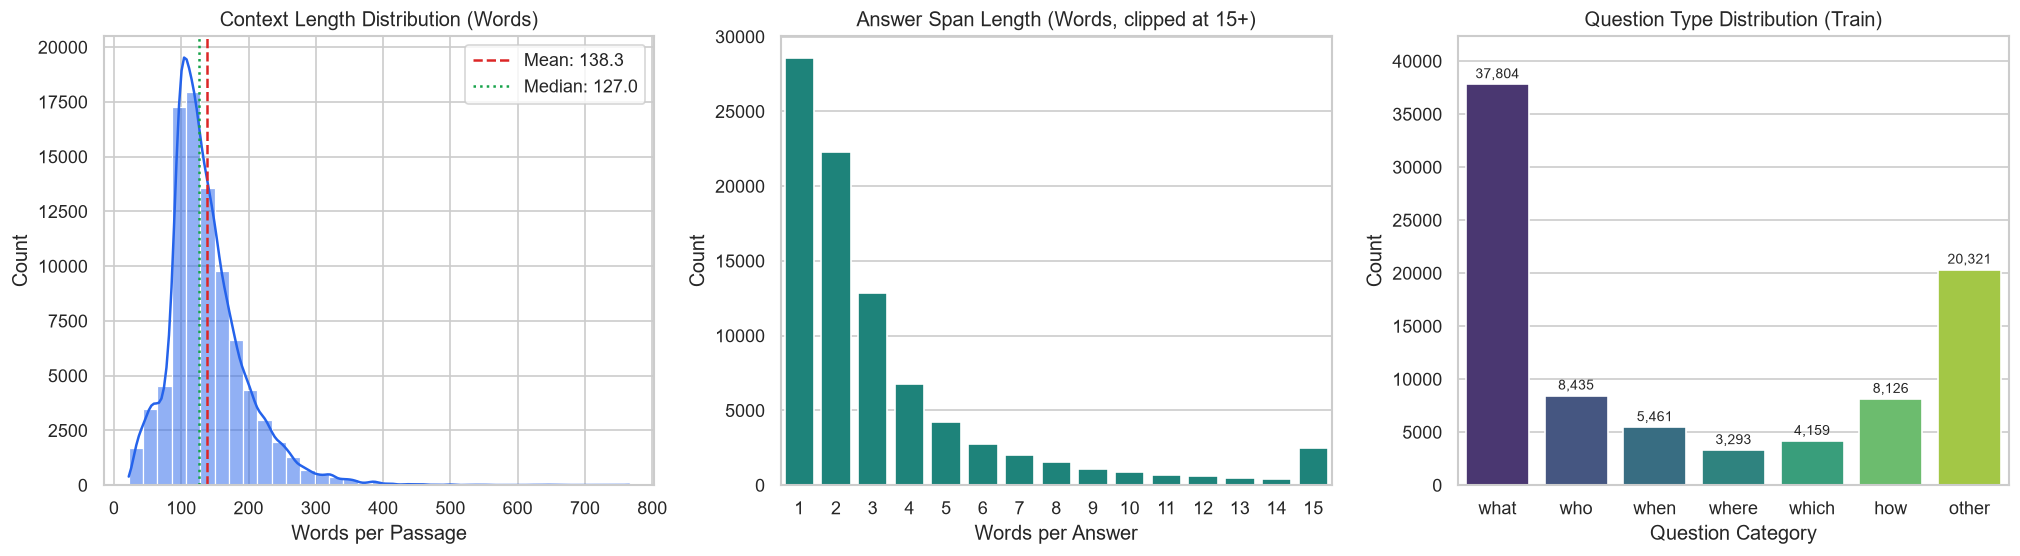

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), dpi=120)

# 1. Context word length distribution
sns.histplot(train_eda_df["context_words"], bins=35, kde=True, color="#2563eb", ax=axes[0])
axes[0].axvline(train_eda_df["context_words"].mean(), color="#dc2626", linestyle="--", label=f"Mean: {train_eda_df['context_words'].mean():.1f}")
axes[0].axvline(train_eda_df["context_words"].median(), color="#16a34a", linestyle=":", label=f"Median: {train_eda_df['context_words'].median():.1f}")
axes[0].set_title("Context Length Distribution (Words)")
axes[0].set_xlabel("Words per Passage")
axes[0].set_ylabel("Count")
axes[0].legend()

# 2. Answer word length distribution (clipped at 15+ words)
clipped_ans = train_eda_df["answer_words"].clip(upper=15)
sns.countplot(x=clipped_ans, color="#0d9488", ax=axes[1])
axes[1].set_title("Answer Span Length (Words, clipped at 15+)")
axes[1].set_xlabel("Words per Answer")
axes[1].set_ylabel("Count")

# 3. Question type distribution
qtype_order = ["what", "who", "when", "where", "which", "how", "other"]
qtype_counts = train_eda_df["question_type"].value_counts().reindex(qtype_order, fill_value=0)
sns.barplot(x=qtype_counts.index, y=qtype_counts.values, hue=qtype_counts.index, palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("Question Type Distribution (Train)")
axes[2].set_xlabel("Question Category")
axes[2].set_ylabel("Count")
offset_y = max(qtype_counts.values) * 0.015
for i, v in enumerate(qtype_counts.values):
    axes[2].text(i, v + offset_y, f"{v:,}", ha="center", fontsize=8.5)
axes[2].set_ylim(0, max(qtype_counts.values) * 1.12)

plt.tight_layout()
plt.show()


### 1.1 Linguistic & Entity Profiling with spaCy (`en_core_web_sm`)
Using **spaCy**, we inspect the linguistic structure of SQuAD questions and ground-truth answers across a 3,000-example sample:
- **Named Entity Recognition (NER):** Identifies what fraction of SQuAD answers correspond to entities such as `DATE`, `PERSON`, `ORG`, `GPE`, `CARDINAL`, or `NORP`.
- **Part-of-Speech (POS) Tagging:** Contrasts the syntactic composition of answers (heavily nominal/proper-noun/numerical) against questions (interrogative/verbal).


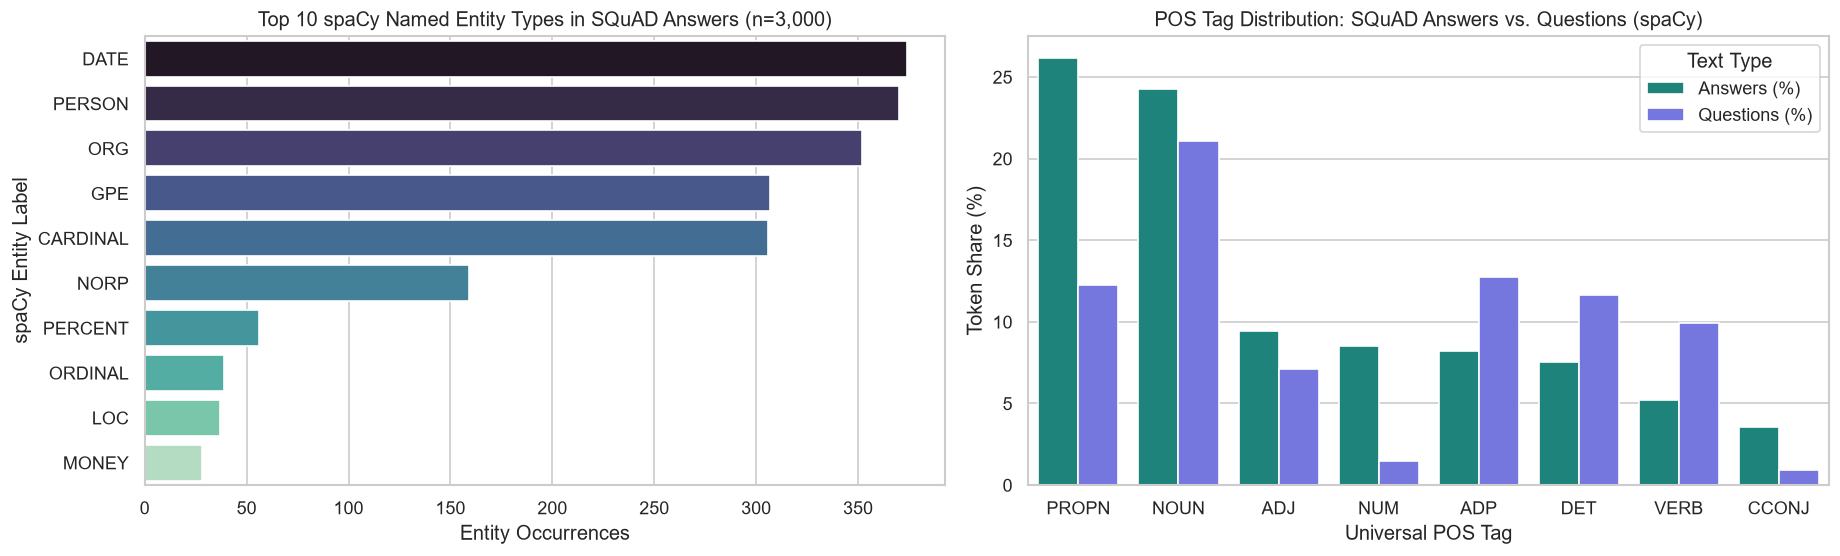

In [5]:
sample_subset = squad_ds["train"].shuffle(seed=SEED).select(range(3000))
sample_answers = [ex["answers"]["text"][0] for ex in sample_subset]
sample_questions = [ex["question"] for ex in sample_subset]

ans_spacy = analyze_spacy_ner_and_pos(sample_answers, batch_size=256)
q_spacy = analyze_spacy_ner_and_pos(sample_questions, batch_size=256)

top_ner_series = pd.Series(ans_spacy["ner_counts"]).head(10)

# Normalize POS distributions into percentages for fair answer vs. question comparison
ans_pos_s = pd.Series(ans_spacy["pos_counts"])
q_pos_s = pd.Series(q_spacy["pos_counts"])
top_pos_tags = list((ans_pos_s / ans_pos_s.sum()).nlargest(8).index)

pos_compare_df = pd.DataFrame(
    {
        "POS Tag": top_pos_tags,
        "Answers (%)": [(ans_pos_s.get(tag, 0) / ans_pos_s.sum()) * 100.0 for tag in top_pos_tags],
        "Questions (%)": [(q_pos_s.get(tag, 0) / q_pos_s.sum()) * 100.0 for tag in top_pos_tags],
    }
).melt(id_vars="POS Tag", var_name="Text Type", value_name="Share (%)")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8), dpi=120)

sns.barplot(
    x=top_ner_series.values,
    y=top_ner_series.index,
    hue=top_ner_series.index,
    palette="mako",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Top 10 spaCy Named Entity Types in SQuAD Answers (n=3,000)")
axes[0].set_xlabel("Entity Occurrences")
axes[0].set_ylabel("spaCy Entity Label")

sns.barplot(
    data=pos_compare_df,
    x="POS Tag",
    y="Share (%)",
    hue="Text Type",
    palette=["#0d9488", "#6366f1"],
    ax=axes[1],
)
axes[1].set_title("POS Tag Distribution: SQuAD Answers vs. Questions (spaCy)")
axes[1].set_xlabel("Universal POS Tag")
axes[1].set_ylabel("Token Share (%)")

plt.tight_layout()
plt.show()


## 2. Stage 2: Data Preprocessing
We prepare the text differently for each modeling paradigm:
- **Classical Baseline Preprocessing (NLTK + Scikit-learn):** Sentences are extracted with `nltk.sent_tokenize`, normalized, filtered for English stop words, and projected into a sparse TF-IDF bag-of-words space.
- **Transformer Preprocessing (DistilBERT):** Question and passage pairs are tokenized together (`[CLS] question [SEP] context [SEP]`). Long passages are split into overlapping chunks using `max_length=384` and `doc_stride=128`, while exact character offsets (`answer_start`, `answer_end`) are mapped to token indices (`start_positions`, `end_positions`).


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

sample_ex = squad_ds["train"][0]
sample_sents = nltk.sent_tokenize(sample_ex["context"])
sample_words = nltk.word_tokenize(sample_ex["question"])

vec = TfidfVectorizer(stop_words="english")
tfidf_mat = vec.fit_transform(sample_sents + [sample_ex["question"]])

print(f"Sample Question Tokens (NLTK): {sample_words}")
print(f"Sentences in Sample Passage  : {len(sample_sents)}")
print(f"TF-IDF Matrix Shape          : {tfidf_mat.shape} (sentences + question x vocabulary)")


Sample Question Tokens (NLTK): ['To', 'whom', 'did', 'the', 'Virgin', 'Mary', 'allegedly', 'appear', 'in', '1858', 'in', 'Lourdes', 'France', '?']
Sentences in Sample Passage  : 7
TF-IDF Matrix Shape          : (8, 52) (sentences + question x vocabulary)


In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

tokenized_train = squad_ds["train"].map(
    lambda batch: prepare_train_features(
        batch, tokenizer, max_length=MAX_LENGTH, doc_stride=DOC_STRIDE
    ),
    batched=True,
    remove_columns=squad_ds["train"].column_names,
    desc="Tokenizing full train set",
)

tokenized_val = squad_ds["validation"].map(
    lambda batch: prepare_validation_features(
        batch, tokenizer, max_length=MAX_LENGTH, doc_stride=DOC_STRIDE
    ),
    batched=True,
    remove_columns=squad_ds["validation"].column_names,
    desc="Tokenizing full validation set",
)

tokenized_val_loss = squad_ds["validation"].map(
    lambda batch: prepare_train_features(
        batch, tokenizer, max_length=MAX_LENGTH, doc_stride=DOC_STRIDE
    ),
    batched=True,
    remove_columns=squad_ds["validation"].column_names,
    desc="Tokenizing validation set (eval loss)",
)

print(f"Original Train Examples : {len(squad_ds['train']):,} -> Sliding-Window Features : {len(tokenized_train):,}")
print(f"Original Val Examples   : {len(squad_ds['validation']):,} -> Sliding-Window Features : {len(tokenized_val):,}")


Tokenizing full train set:   0%|          | 0/87599 [00:00<?, ? examples/s]

Tokenizing full validation set:   0%|          | 0/10570 [00:00<?, ? examples/s]

Tokenizing validation set (eval loss):   0%|          | 0/10570 [00:00<?, ? examples/s]

Original Train Examples : 87,599 -> Sliding-Window Features : 88,524
Original Val Examples   : 10,570 -> Sliding-Window Features : 10,784


In [8]:
# Verify character-to-token alignment on a real tokenized training feature
feat_0 = tokenized_train[0]
start_idx = feat_0["start_positions"]
end_idx = feat_0["end_positions"]
decoded_span = tokenizer.decode(feat_0["input_ids"][start_idx : end_idx + 1])

print(f"Original Question       : {squad_ds['train'][0]['question']}")
print(f"Ground-Truth Answer     : {squad_ds['train'][0]['answers']['text'][0]!r}")
print(f"Token Span Indices      : [{start_idx}, {end_idx}]")
print(f"Decoded Token Span      : {decoded_span!r}")


Original Question       : To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
Ground-Truth Answer     : 'Saint Bernadette Soubirous'
Token Span Indices      : [130, 137]
Decoded Token Span      : 'saint bernadette soubirous'


## 3. Stage 3: Model Implementation
### 3.1 Classical Baseline: TF-IDF + Cosine Similarity Sentence Retrieval
Our baseline treats extractive QA as an intra-passage information retrieval problem: it splits each passage into sentences using NLTK, builds TF-IDF vectors for each sentence and the question, and returns the sentence with the highest cosine similarity across all **10,570** validation examples.


In [9]:
baseline_model = TfidfSentenceBaseline(stop_words="english")

t0 = time.perf_counter()
baseline_metrics, baseline_preds = baseline_model.evaluate_dataset(squad_ds["validation"])
baseline_time = time.perf_counter() - t0

print(f"TF-IDF Baseline Evaluation Completed on {baseline_metrics['num_examples']:,} examples in {baseline_time:.2f}s")
print(f"Baseline Exact Match (EM): {baseline_metrics['exact_match']:.2f}%")
print(f"Baseline Token F1        : {baseline_metrics['f1']:.2f}%")

print("\nSample Baseline Predictions:")
for row in baseline_metrics["per_example"][:2]:
    print(f"- Q: {row['question']}")
    print(f"  Ground Truth: {row['ground_truths']}")
    print(f"  TF-IDF Pred : {row['prediction'][:180]}... (F1={row['f1']:.1f}%)")


TF-IDF Baseline Evaluation Completed on 10,570 examples in 28.30s
Baseline Exact Match (EM): 0.26%
Baseline Token F1        : 19.38%

Sample Baseline Predictions:
- Q: Which NFL team represented the AFC at Super Bowl 50?
  Ground Truth: ['Denver Broncos', 'Denver Broncos', 'Denver Broncos']
  TF-IDF Pred : Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season.... (F1=0.0%)
- Q: Which NFL team represented the NFC at Super Bowl 50?
  Ground Truth: ['Carolina Panthers', 'Carolina Panthers', 'Carolina Panthers']
  TF-IDF Pred : Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season.... (F1=0.0%)


### 3.2 Extractive Transformer Model: Fine-Tuning DistilBERT on Full SQuAD v1.1
We load `distilbert-base-uncased` with a token-level Question Answering head (`AutoModelForQuestionAnswering`), which projects each token hidden state into two logits: **start** and **end**.

Hyperparameters tuned for full SQuAD v1.1 (~88.5k sliding-window features) on **4 GB GPU VRAM**:
- `per_device_train_batch_size = 8` with `gradient_accumulation_steps = 2` (effective batch size = 16)
- `fp16 = True` (mixed precision on RTX 3050 Tensor Cores)
- `learning_rate = 3e-5`, `weight_decay = 0.01`, `warmup_steps = 0.1`, `num_train_epochs = 2`
- `eval_strategy = "epoch"`, `save_strategy = "epoch"`, `load_best_model_at_end = True`


In [10]:
shutil.rmtree(OUTPUT_DIR, ignore_errors=True)
model = AutoModelForQuestionAnswering.from_pretrained(MODEL_CHECKPOINT)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_steps=0.1,
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,
    logging_steps=250,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val_loss,
    processing_class=tokenizer,
    data_collator=default_data_collator,
)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

train_start = time.perf_counter()
train_result = trainer.train()
train_elapsed = time.perf_counter() - train_start

print(f"\nFine-tuning finished in {train_elapsed:.1f}s ({train_elapsed / 60:.2f} min)")
print(f"Final Train Loss: {train_result.training_loss:.4f}")
if torch.cuda.is_available():
    peak_mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    print(f"Peak GPU Memory Allocated: {peak_mem_mb:.1f} MB")

os.makedirs(SAVED_MODEL_DIR, exist_ok=True)
trainer.save_model(SAVED_MODEL_DIR)
tokenizer.save_pretrained(SAVED_MODEL_DIR)
print(f"Best model and tokenizer saved to: {os.path.abspath(SAVED_MODEL_DIR)}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
qa_outputs.weight       | MISSING    | 
qa_outputs.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,1.138777,1.144482
2,0.873451,1.103709


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning finished in 3380.3s (56.34 min)
Final Train Loss: 1.3170
Peak GPU Memory Allocated: 1759.0 MB


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model and tokenizer saved to: C:\Users\z64x\Desktop\Proiect NLP\saved_model\distilbert-squad


## 4. Stage 4: Evaluation, Visualization & Error Analysis
We run inference across all **10,570** validation examples, apply `postprocess_qa_predictions` to reconstruct character spans in the original passages, and evaluate using official SQuAD v1.1 **Exact Match (EM)** and **F1**.


In [11]:
raw_val_output = trainer.predict(tokenized_val.remove_columns(["example_id", "offset_mapping"]))
distilbert_preds, distilbert_nbest = postprocess_qa_predictions(
    examples=squad_ds["validation"],
    features=tokenized_val,
    raw_predictions=raw_val_output.predictions,
    n_best_size=20,
    max_answer_length=MAX_ANSWER_LENGTH,
)

distilbert_metrics = evaluate_predictions(distilbert_preds, squad_ds["validation"])

print(f"Fine-Tuned DistilBERT Exact Match (EM) [n={distilbert_metrics['num_examples']:,}]: {distilbert_metrics['exact_match']:.2f}%")
print(f"Fine-Tuned DistilBERT Token F1        [n={distilbert_metrics['num_examples']:,}]: {distilbert_metrics['f1']:.2f}%")


Fine-Tuned DistilBERT Exact Match (EM) [n=10,570]: 77.08%
Fine-Tuned DistilBERT Token F1        [n=10,570]: 85.41%


,Model,Exact Match (%),F1 Score (%)
0,TF-IDF Sentence Baseline (NLTK + Sklearn),0.26,19.38
1,"Fine-Tuned DistilBERT (Full SQuAD, 2 epochs)",77.08,85.41


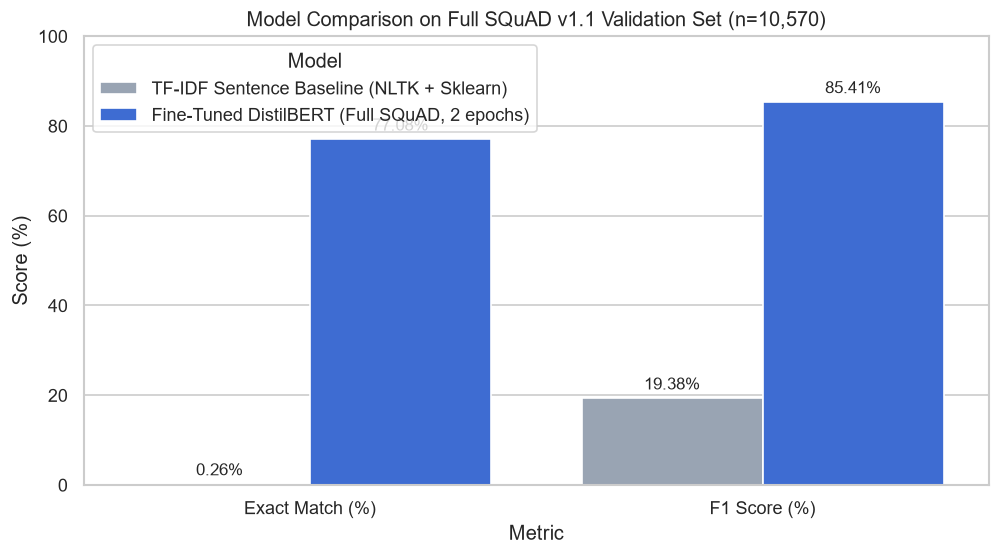

In [12]:
comparison_df = pd.DataFrame(
    [
        {
            "Model": "TF-IDF Sentence Baseline (NLTK + Sklearn)",
            "Exact Match (%)": round(baseline_metrics["exact_match"], 2),
            "F1 Score (%)": round(baseline_metrics["f1"], 2),
        },
        {
            "Model": "Fine-Tuned DistilBERT (Full SQuAD, 2 epochs)",
            "Exact Match (%)": round(distilbert_metrics["exact_match"], 2),
            "F1 Score (%)": round(distilbert_metrics["f1"], 2),
        },
    ]
)
display(comparison_df)

melted_comp = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score (%)")
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=120)
sns.barplot(data=melted_comp, x="Metric", y="Score (%)", hue="Model", palette=["#94a3b8", "#2563eb"], ax=ax)
ax.set_ylim(0, 100)
ax.set_title("Model Comparison on Full SQuAD v1.1 Validation Set (n=10,570)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=10)
plt.tight_layout()
plt.show()


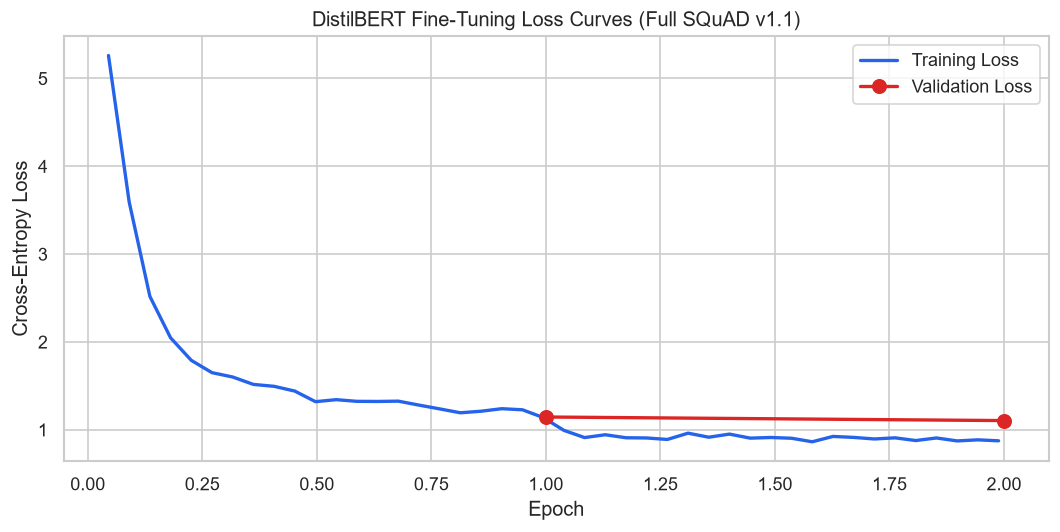

In [13]:
log_df = pd.DataFrame(trainer.state.log_history)
train_logs = log_df[log_df["loss"].notna()][["step", "epoch", "loss"]]
eval_logs = log_df[log_df["eval_loss"].notna()][["epoch", "eval_loss"]]

fig, ax = plt.subplots(figsize=(9, 4.6), dpi=120)
if not train_logs.empty:
    ax.plot(train_logs["epoch"], train_logs["loss"], label="Training Loss", color="#2563eb", linewidth=2)
if not eval_logs.empty:
    ax.plot(eval_logs["epoch"], eval_logs["eval_loss"], marker="o", markersize=8, label="Validation Loss", color="#dc2626", linewidth=2)

ax.set_title("DistilBERT Fine-Tuning Loss Curves (Full SQuAD v1.1)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend()
plt.tight_layout()
plt.show()


,count,distilbert_em,distilbert_f1,baseline_f1
question_type,,,,
what,4766,74.88,84.31,20.74
who,1096,84.85,89.11,16.46
when,696,88.07,91.68,16.03
where,433,71.13,82.09,20.29
which,455,79.12,85.50,16.88
how,1090,75.14,84.58,18.46
other,2034,76.11,84.98,19.77


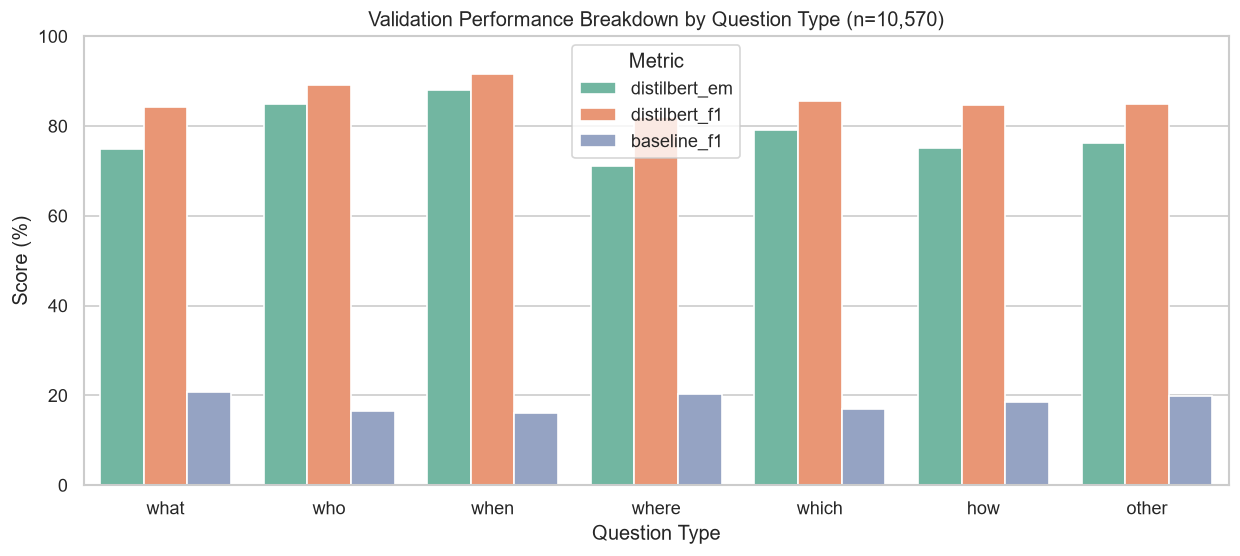

In [14]:
distil_ex_df = pd.DataFrame(distilbert_metrics["per_example"])
base_ex_df = pd.DataFrame(baseline_metrics["per_example"])

qtype_order = ["what", "who", "when", "where", "which", "how", "other"]
qtype_summary = (
    distil_ex_df.groupby("question_type")
    .agg(
        count=("id", "count"),
        distilbert_em=("em", "mean"),
        distilbert_f1=("f1", "mean"),
    )
    .reindex([q for q in qtype_order if q in distil_ex_df["question_type"].unique()])
    .round(2)
)
qtype_summary["baseline_f1"] = (
    base_ex_df.groupby("question_type")["f1"].mean().reindex(qtype_summary.index).round(2)
)
display(qtype_summary)

plot_qtype = qtype_summary.reset_index().melt(
    id_vars=["question_type", "count"],
    value_vars=["distilbert_em", "distilbert_f1", "baseline_f1"],
    var_name="Metric",
    value_name="Score (%)",
)
fig, ax = plt.subplots(figsize=(10.5, 4.8), dpi=120)
sns.barplot(data=plot_qtype, x="question_type", y="Score (%)", hue="Metric", palette="Set2", ax=ax)
ax.set_ylim(0, 100)
ax.set_title("Validation Performance Breakdown by Question Type (n=10,570)")
ax.set_xlabel("Question Type")
ax.set_ylabel("Score (%)")
plt.tight_layout()
plt.show()


### 4.1 Performance Breakdown by Answer Named Entity Type (spaCy)
We run **spaCy** NER over all 10,570 primary validation ground-truth answers to inspect how well DistilBERT performs on structured entity spans (`DATE`, `PERSON`, `ORG`, `GPE`, `CARDINAL`, `NORP`, `LOC`) versus descriptive `NON-ENTITY` phrases.


,count,distilbert_em,distilbert_f1
answer_entity_type,,,
DATE,1078,88.68,92.53
PERSON,1132,83.92,88.93
ORG,1173,77.41,86.19
GPE,603,79.77,87.73
CARDINAL,983,81.38,87.73
NORP,331,70.39,84.15
LOC,122,69.67,80.39
NON-ENTITY,4591,71.88,81.84


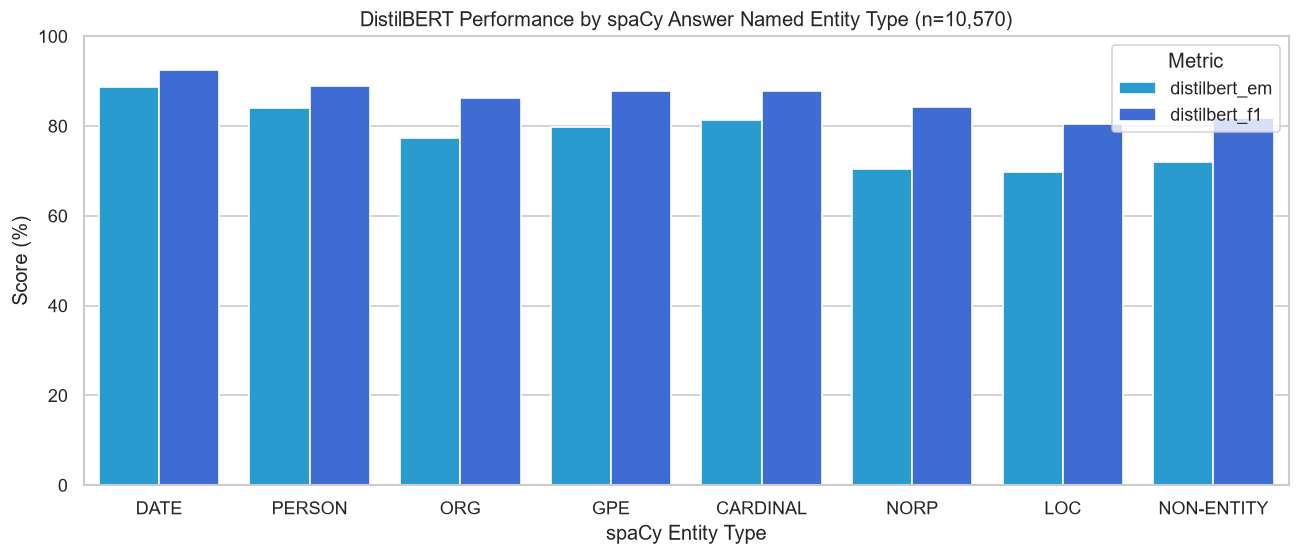

In [15]:
val_primary_answers = [
    gts[0] if gts else "" for gts in distil_ex_df["ground_truths"]
]
val_spacy = analyze_spacy_ner_and_pos(val_primary_answers, batch_size=256)
distil_ex_df["answer_entity_type"] = val_spacy["primary_entities"]

target_entities = ["DATE", "PERSON", "ORG", "GPE", "CARDINAL", "NORP", "LOC", "NON-ENTITY"]
available_entities = [e for e in target_entities if e in distil_ex_df["answer_entity_type"].values]

entity_summary = (
    distil_ex_df[distil_ex_df["answer_entity_type"].isin(available_entities)]
    .groupby("answer_entity_type")
    .agg(
        count=("id", "count"),
        distilbert_em=("em", "mean"),
        distilbert_f1=("f1", "mean"),
    )
    .reindex(available_entities)
    .round(2)
)
display(entity_summary)

plot_ent = entity_summary.reset_index().melt(
    id_vars=["answer_entity_type", "count"],
    value_vars=["distilbert_em", "distilbert_f1"],
    var_name="Metric",
    value_name="Score (%)",
)
fig, ax = plt.subplots(figsize=(11, 4.8), dpi=120)
sns.barplot(data=plot_ent, x="answer_entity_type", y="Score (%)", hue="Metric", palette=["#0ea5e9", "#2563eb"], ax=ax)
ax.set_ylim(0, 100)
ax.set_title("DistilBERT Performance by spaCy Answer Named Entity Type (n=10,570)")
ax.set_xlabel("spaCy Entity Type")
ax.set_ylabel("Score (%)")
plt.tight_layout()
plt.show()


In [16]:
print("=" * 80)
print("QUALITATIVE SHOWCASE: 5 EXACT MATCH PREDICTIONS")
print("=" * 80)
correct_cases = distil_ex_df[distil_ex_df["em"] == 100.0].head(5)
for i, (_, row) in enumerate(correct_cases.iterrows(), start=1):
    print(f"\n[Correct #{i}] ({row['question_type'].upper()} | NER={row['answer_entity_type']}) Q: {row['question']}")
    print(f"  Ground Truths   : {row['ground_truths']}")
    print(f"  DistilBERT Pred : {row['prediction']!r} (EM={row['em']:.0f}%, F1={row['f1']:.1f}%)")

print("\n" + "=" * 80)
print("ERROR ANALYSIS: 5 FAILURE / PARTIAL-MATCH CASES")
print("=" * 80)
error_cases = distil_ex_df[distil_ex_df["em"] == 0.0].sort_values(by="f1", ascending=True).head(5)
for i, (_, row) in enumerate(error_cases.iterrows(), start=1):
    base_pred = baseline_preds.get(row["id"], "")
    diag = "Partial span overlap / boundary mismatch" if row["f1"] > 0 else "Incorrect span selected"
    print(f"\n[Error #{i}] ({row['question_type'].upper()} | NER={row['answer_entity_type']}) Q: {row['question']}")
    print(f"  Ground Truths   : {row['ground_truths']}")
    print(f"  DistilBERT Pred : {row['prediction']!r} (F1={row['f1']:.1f}%) -> {diag}")
    print(f"  TF-IDF Baseline : {base_pred[:140]!r}...")
    print(f"  Context Snippet : {row['context'][:220]}...")


QUALITATIVE SHOWCASE: 5 EXACT MATCH PREDICTIONS

[Correct #1] (WHICH | NER=GPE) Q: Which NFL team represented the AFC at Super Bowl 50?
  Ground Truths   : ['Denver Broncos', 'Denver Broncos', 'Denver Broncos']
  DistilBERT Pred : 'Denver Broncos' (EM=100%, F1=100.0%)

[Correct #2] (WHICH | NER=NON-ENTITY) Q: Which NFL team represented the NFC at Super Bowl 50?
  Ground Truths   : ['Carolina Panthers', 'Carolina Panthers', 'Carolina Panthers']
  DistilBERT Pred : 'Carolina Panthers' (EM=100%, F1=100.0%)

[Correct #3] (WHERE | NER=GPE) Q: Where did Super Bowl 50 take place?
  Ground Truths   : ['Santa Clara, California', "Levi's Stadium", "Levi's Stadium in the San Francisco Bay Area at Santa Clara, California."]
  DistilBERT Pred : "Levi's Stadium" (EM=100%, F1=100.0%)

[Correct #4] (WHAT | NER=NON-ENTITY) Q: What color was used to emphasize the 50th anniversary of the Super Bowl?
  Ground Truths   : ['gold', 'gold', 'gold']
  DistilBERT Pred : 'gold' (EM=100%, F1=100.0%)

[Correct #5]

### 4.2 Custom Passage & Question Inference Test
Finally, we test `ExtractiveQAInference` using the saved full-SQuAD local model (`./saved_model/distilbert-squad`), alongside `annotate_answer_entity` (spaCy) and `TfidfSentenceBaseline` (NLTK + Scikit-learn).


In [17]:
qa_engine = ExtractiveQAInference(model_path=SAVED_MODEL_DIR)

custom_tests = [
    {
        "context": (
            "The Transformer architecture was introduced in 2017 by Vaswani et al. in the landmark "
            "paper 'Attention Is All You Need'. Unlike recurrent neural networks, Transformers rely "
            "entirely on self-attention mechanisms, enabling massive parallelization during training."
        ),
        "question": "When was the Transformer architecture introduced?",
    },
    {
        "context": (
            "DistilBERT is a small, fast, cheap, and light Transformer model trained by distilling "
            "BERT-base. It retains 97% of BERT's language understanding capabilities while having "
            "40% fewer parameters and running 60% faster."
        ),
        "question": "How much of BERT's language understanding does DistilBERT retain?",
    },
    {
        "context": (
            "Bucharest is the capital and largest city of Romania, located in the southeast of the "
            "country along the banks of the Dambovita River. It became the capital of Romania in 1862."
        ),
        "question": "Which river flows through Bucharest?",
    },
]

for idx, item in enumerate(custom_tests, start=1):
    bert_out = qa_engine.predict(item["context"], item["question"], top_k=3)
    ent_label = annotate_answer_entity(bert_out["answer"]) or "NON-ENTITY"
    base_out = baseline_model.predict(item["context"], item["question"])
    print(f"\n[Custom Test {idx}] Q: {item['question']}")
    print(f"  DistilBERT Answer : {bert_out['answer']!r} (prob={bert_out['score']*100:.1f}%, NER={ent_label}, chars=[{bert_out['start_char']}:{bert_out['end_char']}])")
    print(f"  TF-IDF Baseline   : {base_out['answer']!r} (cosine={base_out['score']:.3f})")


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


[Custom Test 1] Q: When was the Transformer architecture introduced?
  DistilBERT Answer : '2017' (prob=96.5%, NER=DATE, chars=[47:51])
  TF-IDF Baseline   : 'The Transformer architecture was introduced in 2017 by Vaswani et al.' (cosine=0.564)

[Custom Test 2] Q: How much of BERT's language understanding does DistilBERT retain?
  DistilBERT Answer : '97%' (prob=96.1%, NER=PERCENT, chars=[108:111])
  TF-IDF Baseline   : "It retains 97% of BERT's language understanding capabilities while having 40% fewer parameters and running 60% faster." (cosine=0.220)

[Custom Test 3] Q: Which river flows through Bucharest?
  DistilBERT Answer : 'Dambovita River' (prob=89.7%, NER=ORG, chars=[117:132])
  TF-IDF Baseline   : 'Bucharest is the capital and largest city of Romania, located in the southeast of the country along the banks of the Dambovita River.' (cosine=0.258)
